# Lab 3.5 — How does text become GPT-2 token IDs?

A character occupied one embedding row in Lab 3.2. Byte-pair encoding (BPE) starts from bytes and learns reusable pieces. Follow one merge before inspecting a real vocabulary.

## Train three merges on banana

Count adjacent pairs, merge the most frequent non-overlapping occurrences from left to right, then recount. Ties here follow first occurrence. Predict which pair wins the first tie and how many tokens disappear.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from collections import Counter
pieces = {i: bytes([i]) for i in range(256)}
def merge(seq, pair, token):
    merged = []
    i = 0
    while i < len(seq):
        if tuple(seq[i:i+2]) == pair:
            merged.append(token)
            i += 2
        else:
            merged.append(seq[i])
            i += 1
    return merged

seq = list(b"banana")
rules = []
for token in range(256,259):
    pair = Counter(zip(seq,seq[1:])).most_common(1)[0][0]
    pieces[token] = pieces[pair[0]] + pieces[pair[1]]
    rules.append(pair)
    seq = merge(seq, pair, token)
    print(pair, "→", pieces[token], [pieces[i] for i in seq])

(97, 110) → b'an' [b'b', b'an', b'an', b'a']
(98, 256) → b'ban' [b'ban', b'an', b'a']
(257, 256) → b'banan' [b'banan', b'a']


## Compare exact round trips

Apply the learned merges in training order. GPT-2 additionally splits text into chunks before applying its own ranked merges, so whitespace affects the IDs. Predict which strings share a token. The real tokenizer file comes from the pinned public GPT-2 checkpoint.

'banana' toy [258, 97] GPT-2 [3820, 2271]
' banana' toy [32, 258, 97] GPT-2 [25996]
'banana\n' toy [258, 97, 10] GPT-2 [3820, 2271, 198]
'café 🍌' toy [99, 97, 102, 195, 169, 32, 240, 159, 141, 140] GPT-2 [66, 1878, 2634, 12520, 235, 234]
Out[2]: PosixPath('checkpoints/lab35/bpe_trace.npz')


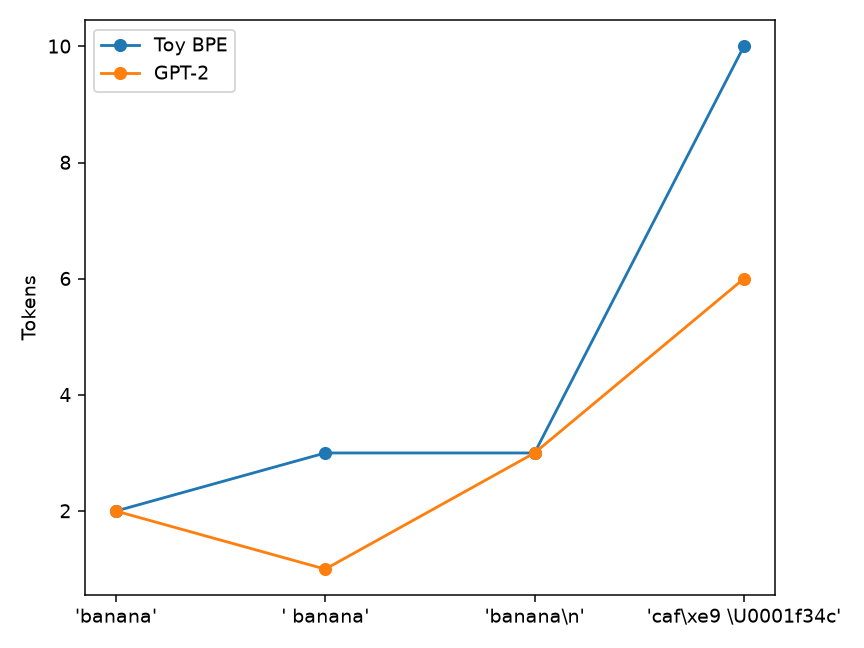

In [2]:
from tokenizers import Tokenizer
from llm_lab.assets import asset
real = Tokenizer.from_file(str(asset("tokenizer.json")))
strings = ["banana", " banana", "banana\n", "café 🍌"]
lengths = []
for text in strings:
    tiny = list(text.encode("utf8"))
    for token, pair in enumerate(rules, 256):
        tiny = merge(tiny, pair, token)
    assert b"".join(pieces[i] for i in tiny).decode() == text
    encoded = real.encode(text).ids
    assert real.decode(encoded) == text
    print(repr(text), "toy", tiny, "GPT-2", encoded)
    lengths.append([len(tiny), len(encoded)])
plt.plot(range(4), lengths, marker="o")
plt.xticks(range(4), [ascii(s) for s in strings])
plt.ylabel("Tokens"); plt.legend(["Toy BPE", "GPT-2"])
show(35, "token_counts")
record(35, "bpe_trace", rules=rules, counts=lengths)

## Reading the result

The toy vocabulary contains every individual byte, so it can spell an unseen emoji even if training never saw that character. The learned merges govern how many pieces are needed. When comparing language-model losses across these tokenizers, a “token” covers different amounts of text. A common unit such as bits per UTF-8 byte lets you compare the same underlying text. [GPT-2 tokenizer implementation](https://github.com/openai/gpt-2/blob/master/src/encoder.py)